# What does the database actually read for `SELECT * FROM users WHERE email = ?`

The companion notebook to `notes.pdf`. You build a small `users` table in SQLite, then open the database
**file** and read its pages yourself: the page size in the header, the table's B-tree, the scan, the index's
B-tree, the exact pages one lookup reads, and the questions the sort order can and can't answer.

Everything here is standard library (`sqlite3`, plus a page decoder of about sixty lines that follows the
[file format spec](https://www.sqlite.org/fileformat2.html)). It runs in seconds. Set `FULL = True` for the
notes' table of 1,000,000 rows: same seed, same rows, and with SQLite 3.45.3 the same page numbers as
the notes, to the page.

In [1]:
FULL = False                      # True: the notes' table (about 30 s for the whole notebook, 80 MB on disk)
N = 1_000_000 if FULL else 100_000

import os
import random
import shutil
import sqlite3
import string
import tempfile

try:
    import matplotlib.pyplot as plt
except ImportError:               # the one chart is optional; its numbers are printed too
    plt = None

SEED, TARGET = 2026, "kiwi@mail.test"
DOMAINS = ["mail.test", "post.test", "inbox.test", "box.test"]
CITIES = ["Almaty", "Berlin", "Cairo", "Lima", "Oslo", "Paris", "Seoul", "Tokyo"]
LINE = "SELECT * FROM users WHERE email = ?"
WORK = tempfile.mkdtemp(prefix="db-index-")
DB = os.path.join(WORK, "users.db")


def build(path, rows):
    """users(id, email, city, age): made-up emails on .test domains, exactly one of them kiwi@mail.test."""
    con = sqlite3.connect(path)
    con.execute("CREATE TABLE users (id INTEGER PRIMARY KEY, email TEXT, city TEXT, age INTEGER)")
    rng = random.Random(SEED)
    target_at = rng.randrange(rows)

    def gen():
        for i in range(rows):
            local = "kiwi" if i == target_at else "".join(rng.choices(string.ascii_lowercase, k=8))
            email = TARGET if i == target_at else f"{local}@{rng.choice(DOMAINS)}"
            yield email, rng.choice(CITIES), rng.randint(18, 80)

    con.executemany("INSERT INTO users (email, city, age) VALUES (?, ?, ?)", gen())
    con.commit()
    return con


def plan(sql, args=()):
    """SQLite's own answer to 'how will you run this?', on one line."""
    return " / ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql, args))


con = build(DB, N)
print(f"SQLite {sqlite3.sqlite_version} · {N:,} rows · {os.path.getsize(DB):,} bytes in {DB}")

SQLite 3.45.3 · 100,000 rows · 3,522,560 bytes in /var/folders/wm/7lpcd5bn469gngbhdy6r71vm0000gn/T/db-index-30v0hfm8/users.db


## 1. The line you write

One row, by email. Our run on the full table: `kiwi@mail.test` is row 124,907, in Lima,
age 25. On the small table it's another id: the rows are different, the picture isn't.

In [2]:
print(con.execute(LINE, (TARGET,)).fetchall())

[(15614, 'kiwi@mail.test', 'Almaty', 64)]


## 2. The file is pages

A SQLite database is one file cut into pages of the same size. The first 100 bytes of the file say
how big a page is (bytes `16-17`) and how many there are (bytes `28-31`). A page is read whole, so pages are what
a query costs.

Every table is a B-tree of those pages: leaves that hold the rows in id order, and signpost pages above them.
Our run: 1 root page, 22 signpost pages,
8,597 leaves of about 116 rows each.

In [3]:
with open(DB, "rb") as f:
    head = f.read(100)
SIZE = int.from_bytes(head[16:18], "big")
print(head[:16], "· page size", SIZE, "· pages in the file", int.from_bytes(head[28:32], "big"))
print("PRAGMA page_size →", con.execute("PRAGMA page_size").fetchone()[0])
ROOT = dict(con.execute("SELECT name, rootpage FROM sqlite_master WHERE rootpage > 0"))
print("root pages:", ROOT)

b'SQLite format 3\x00' · page size 4096 · pages in the file 860
PRAGMA page_size → 4096
root pages: {'users': 2}


SQLite can describe its own pages through the `dbstat` table (most builds have it). Each row is one page:
which tree it belongs to, where it sits (`path`), its type and how many cells it holds.

In [4]:
try:
    for row in con.execute("SELECT pagetype, count(*), sum(ncell) FROM dbstat WHERE name = 'users' "
                           "GROUP BY pagetype"):
        print(row)
    print(con.execute("SELECT pageno, path, pagetype, ncell FROM dbstat WHERE name = 'users' LIMIT 4").fetchall())
except sqlite3.OperationalError as e:
    print("this SQLite build has no dbstat:", e, "· the page reader below needs nothing from it")

('internal', 3, 855)
('leaf', 856, 100000)
[(2, '/', 'internal', 1), (474, '/000/', 'internal', 413), (3, '/000/000/', 'leaf', 124), (4, '/000/001/', 'leaf', 120)]


Now without SQLite's help. Each B-tree page starts with a header: byte 0 is the page type (`0x0D` table leaf,
`0x05` table interior, `0x0A` index leaf, `0x02` index interior), bytes `3-4` the number of cells, and on
interior pages bytes `8-11` the right-most child. After the header comes an array of 2-byte offsets, one per
cell, and the cells themselves are packed from the end of the page backwards. A cell is a little record:
varints for its size and the rowid, a header of column types, then the values.

This is the whole reader. It follows the [file format spec](https://www.sqlite.org/fileformat2.html) (its
B-tree pages and record format sections); there is no SQLite call in it.

In [5]:
KIND = {2: "index interior", 5: "table interior", 10: "index leaf", 13: "table leaf"}


def varint(b, i):
    v = 0
    for k in range(8):
        v = (v << 7) | (b[i + k] & 0x7F)
        if b[i + k] < 0x80:
            return v, i + k + 1
    return (v << 8) | b[i + 8], i + 9


def record(b, i):
    """Column values of one record. Rows here are short, so no cell spills onto overflow pages."""
    hlen, j = varint(b, i)
    types, out, p = [], [], i + hlen
    while j < i + hlen:
        t, j = varint(b, j)
        types.append(t)
    for t in types:
        if t == 0:
            out.append(None)                                  # NULL, and the id column (it is the rowid)
        elif t in (8, 9):
            out.append(t - 8)
        elif t <= 6:
            n = (0, 1, 2, 3, 4, 6, 8)[t]
            out.append(int.from_bytes(b[p:p + n], "big", signed=True))
            p += n
        else:                                                 # odd ≥ 13: text of (t - 13) / 2 bytes
            n = (t - 13) // 2
            out.append(b[p:p + n].decode())
            p += n
    return out


READS = []                                                    # every page we read, in order
FILE = open(DB, "rb")                                         # sees every later write: same file


def raw(pgno):
    FILE.seek((pgno - 1) * SIZE)
    return FILE.read(SIZE)


def header(pgno):
    """(page type, number of cells) from the page header alone."""
    b = raw(pgno)
    h = 100 if pgno == 1 else 0
    return KIND[b[h]], int.from_bytes(b[h + 3:h + 5], "big")


def page(pgno):
    """One page, decoded: its type, its cells, its right-most child."""
    READS.append(pgno)
    b = raw(pgno)
    h = 100 if pgno == 1 else 0
    kind, ncell = KIND[b[h]], int.from_bytes(b[h + 3:h + 5], "big")
    interior = b[h] in (2, 5)
    ptrs = h + (12 if interior else 8)
    cells = []
    for k in range(ncell):
        off = int.from_bytes(b[ptrs + 2 * k:ptrs + 2 * k + 2], "big")
        if b[h] == 5:                                         # table interior: child page, largest rowid on its left
            cells.append((int.from_bytes(b[off:off + 4], "big"), varint(b, off + 4)[0]))
        elif b[h] == 13:                                      # table leaf: size, rowid, record
            _, j = varint(b, off)
            rowid, j = varint(b, j)
            cells.append((rowid, [rowid] + record(b, j)[1:]))
        elif b[h] == 2:                                       # index interior: child page, size, record
            _, j = varint(b, off + 4)
            cells.append((int.from_bytes(b[off:off + 4], "big"), record(b, j)))
        else:                                                 # index leaf: size, record
            _, j = varint(b, off)
            cells.append((None, record(b, j)))
    right = int.from_bytes(b[h + 8:h + 12], "big") if interior else None
    return {"pgno": pgno, "kind": kind, "interior": interior, "cells": cells, "right": right, "raw": b}


def levels(root):
    """Page numbers per level, root first (only the signpost pages are decoded)."""
    out, level = [], [root]
    while True:
        out.append(level)
        if "leaf" in header(level[0])[0]:                     # every leaf is at the same depth
            return out
        pages = [page(p) for p in level]
        level = [c for p in pages for c in [c for c, _ in p["cells"]] + [p["right"]]]


def leaves(root):
    """Every leaf of a tree, left to right: the order a scan reads them."""
    p = page(root)
    if not p["interior"]:
        yield p
        return
    for child in [c for c, _ in p["cells"]] + [p["right"]]:
        yield from leaves(child)


first = next(leaves(ROOT["users"]))
print(f"page {first['pgno']}: header bytes {first['raw'][:8].hex(' ')} → {first['kind']}, {len(first['cells'])} rows,"
      f" ids {first['cells'][0][0]} … {first['cells'][-1][0]}")
for rowid, row in first["cells"][:3]:
    print("  ", row)
shape = [len(lv) for lv in levels(ROOT["users"])]
print("the table's tree, pages per level:", shape)

page 3: header bytes 0d 00 00 00 7c 01 01 00 → table leaf, 124 rows, ids 1 … 124
   [1, 'iyqywxqk@box.test', 'Tokyo', 33]
   [2, 'achcaxmi@box.test', 'Oslo', 40]
   [3, 'zyuznbio@inbox.test', 'Oslo', 47]
the table's tree, pages per level: [1, 2, 856]


Our run: page 3 is the first leaf, ids 1 to
124; the tree has 3 levels. Page 1 is the file header and the schema;
page 2 is the table's root. Nothing in this layout is ordered by email.

## 3. No index: SQLite reads every page

Ask for the plan first: `SCAN users` means read the table from its first leaf to its last. Then do what the
scan does: walk the leaves left to right and look at every row. Our run met `kiwi@mail.test` on leaf
1,071 of 8,597 (page 1,076), and kept reading, because
`email` isn't unique and another row could match on any later page: 8,620 pages in all.

In [6]:
print(LINE, "→", plan(LINE, (TARGET,)))
READS.clear()
n_leaves, hits = 0, []
for n_leaves, leaf in enumerate(leaves(ROOT["users"]), 1):
    hits += [(n_leaves, leaf["pgno"], row) for _, row in leaf["cells"] if row[1] == TARGET]
print(f"found {hits} · leaves read: {n_leaves:,} · pages read in all (signposts too): {len(READS):,}")

SELECT * FROM users WHERE email = ? → SCAN users


found [(131, 133, [15614, 'kiwi@mail.test', 'Almaty', 64])] · leaves read: 856 · pages read in all (signposts too): 859


## 4. `CREATE INDEX`: a second tree of sorted `(email, id)` pairs

`CREATE INDEX` reads every row, copies out the email and the row's id, sorts the pairs, and writes them into
pages of their own: a second B-tree in the same file. Our run: 6,628 pages, the root on page
8,622 (right after the table's last page), 6,577 leaves of about
151 entries each.

The next cell also writes one test row and deletes it again, as the notes' run did at this point: section 8
looks at what that write changed. (It also keeps the page counts equal to the notes'.)

In [7]:
SIZE_BEFORE = os.path.getsize(DB)


def one_write(row=("probe@box.test", "Oslo", 30)):
    """INSERT one row and commit, compare the file page by page, DELETE it again. Returns {page: tree}."""
    with open(DB, "rb") as f:
        before = f.read()
    con.execute("INSERT INTO users (email, city, age) VALUES (?, ?, ?)", row)
    con.commit()
    with open(DB, "rb") as f:
        after = f.read()
    changed = [i + 1 for i in range(len(after) // SIZE)
               if before[i * SIZE:(i + 1) * SIZE] != after[i * SIZE:(i + 1) * SIZE]]
    owner = {p: name for name, root in ROOT.items() for lv in levels(root) for p in lv}
    con.execute("DELETE FROM users WHERE email = ?", (row[0],))
    con.commit()
    return {p: ("file header" if p == 1 else owner.get(p, "?")) for p in changed}


WRITES = {"no index": one_write()}                            # what one write changes with no index (section 8)
con.execute("CREATE INDEX idx_users_email ON users(email)")
con.commit()
ROOT = dict(con.execute("SELECT name, rootpage FROM sqlite_master WHERE rootpage > 0"))
WRITES["+ index on email"] = one_write()
print(ROOT)
ix_levels = levels(ROOT["idx_users_email"])
print("the index's tree, pages per level:", [len(lv) for lv in ix_levels])
ix_first = page(ix_levels[-1][0])
print(f"its first leaf, page {ix_first['pgno']} ({ix_first['kind']}):", [e for _, e in ix_first["cells"][:4]], "…")
per_leaf = sum(header(p)[1] for p in ix_levels[-1]) / len(ix_levels[-1])
print(f"entries per leaf: {per_leaf:.0f} (rows per leaf in the table:"
      f" {sum(header(p)[1] for p in levels(ROOT['users'])[-1]) / len(levels(ROOT['users'])[-1]):.0f})")

{'users': 2, 'idx_users_email': 861}
the index's tree, pages per level: [1, 5, 651]
its first leaf, page 862 (index leaf): [['aaacmzov@mail.test', 99873], ['aaadtlsy@post.test', 48650], ['aaanaial@box.test', 20839], ['aaanlwsa@post.test', 84964]] …
entries per leaf: 153 (rows per leaf in the table: 117)


Each entry is a record of two values: the email's bytes and the row's id. No city, no age. An entry is shorter
than a row, so a leaf holds more of them (151 against 116 rows).

## 5. Signposts: from the root to the leaf

Above the leaves sit signpost pages. Each holds a row of keys, and between two keys a pointer to the page with
everything in between. A lookup reads the root, finds the first key that is ≥ the one it wants, follows that
pointer, and repeats until it reaches a leaf.

Our run: the root (page 8,622) has 49 keys and
50 children; `kiwi@mail.test` falls between `jzhefufp@mail.test` and
`knahlact@box.test`, which sends it to page 11,158; there it falls between
`kitwblgc@box.test` and `kiwklevr@inbox.test`, which sends it to leaf 11,249,
where it is entry 150 of 152, with id 124,907.

In [8]:
def descend(root, key):
    """The pages one lookup reads, root to leaf. key: an email (index) or an id (table)."""
    path, pgno = [], root
    while True:
        p = page(pgno)
        keys = [(c[1][0] if p["kind"].startswith("index") else (c[1] if p["interior"] else c[0])) for c in p["cells"]]
        if not p["interior"]:
            hit = keys.index(key) if key in keys else None
            path.append((p, hit))
            return path
        b = next((i for i, k in enumerate(keys) if key <= k), len(keys))
        path.append((p, b))
        if p["kind"] == "index interior" and b < len(keys) and keys[b] == key:
            return path                                       # index B-trees keep entries on signpost pages too
        pgno = p["cells"][b][0] if b < len(keys) else p["right"]


READS.clear()
for p, b in descend(ROOT["idx_users_email"], TARGET):
    keys = [c[1][0] for c in p["cells"]]
    if p["interior"]:
        lo = keys[b - 1] if b else "(start)"
        hi = keys[b] if b < len(keys) else "(end)"
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {len(keys):>3} keys: {lo} < {TARGET} ≤ {hi} → child {b + 1}")
    else:
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {len(keys):>3} entries: entry {b + 1} = {p['cells'][b][1]}")
        ROWID = p["cells"][b][1][1]

page    861 index interior    4 keys: fjnbwhrx@inbox.test < kiwi@mail.test ≤ kuopmtca@post.test → child 2
page    998 index interior  133 keys: kiiwmwcn@post.test < kiwi@mail.test ≤ kjlgolhv@inbox.test → child 123
page  1,120 index leaf      153 entries: entry 72 = ['kiwi@mail.test', 15614]


## 6. The id leads down the table's own tree

`SELECT *` wants the whole row, and the index holds only the email and the id. So SQLite takes the id down the
table's tree, whose signposts are ids: our run went through pages 2,
930 and 1,076, where the row is the first of
117. That makes 6 pages in all. The plan names the index:
`SEARCH users USING INDEX idx_users_email (email=?)`.

In [9]:
for p, b in descend(ROOT["users"], ROWID):
    if p["interior"]:
        n = len(p["cells"])
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {n:>3} key{'s' * (n != 1)} → child {b + 1}")
    else:
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {len(p['cells']):>3} rows: {p['cells'][b][1]}")
print(f"pages read for one SELECT *: {len(READS)} → {READS}")
print(LINE, "→", plan(LINE, (TARGET,)))
print("SELECT id … →", plan("SELECT id FROM users WHERE email = ?", (TARGET,)))

page      2 table interior    1 key → child 1
page    474 table interior  413 keys → child 131
page    133 table leaf      119 rows: [15614, 'kiwi@mail.test', 'Almaty', 64]
pages read for one SELECT *: 6 → [861, 998, 1120, 2, 474, 133]
SELECT * FROM users WHERE email = ? → SEARCH users USING INDEX idx_users_email (email=?)
SELECT id … → SEARCH users USING COVERING INDEX idx_users_email (email=?)


`SELECT id` stops after the index's pages: the id is already in the entry (`COVERING INDEX`).

## 7. So that's why: questions the sort order can and can't answer

The index is sorted by email from the first character. **A leading wildcard** (`'%@post.test'`) asks about
the end of the email, so the matches are everywhere: our run found 250,821 of them, on
6,577 of 6,577 leaf pages, and SQLite answered `SCAN users`. **A prefix** is
a range: the 63 emails that start with `kiw` sat on two neighbouring leaves, and the plan was
`SEARCH users USING INDEX idx_users_email (email>? AND email<?)`. Watch `LIKE 'kiw%'`: it ignores case, the index is sorted by exact bytes, so it scans.

SELECT * FROM users WHERE email LIKE '%@post.test' → SCAN users
SELECT * FROM users WHERE email GLOB 'kiw*'      → SEARCH users USING INDEX idx_users_email (email>? AND email<?)
SELECT * FROM users WHERE email LIKE 'kiw%'      → SCAN users


'%@post.test': matches on 651 of 651 leaves · 'kiw*': on leaves [257]


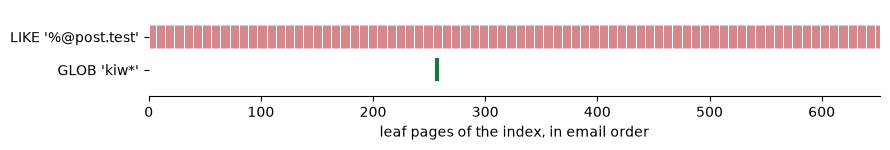

In [10]:
def leaves_with(root, test):
    """Leaf numbers (left to right) that hold at least one entry passing `test`, and how many leaves there are."""
    hit, n = [], 0
    for n, leaf in enumerate(leaves(root), 1):
        if any(test(e) for _, e in leaf["cells"]):
            hit.append(n)
    return hit, n


for sql, arg in [("SELECT * FROM users WHERE email LIKE ?", "%@post.test"),
                 ("SELECT * FROM users WHERE email GLOB ?", "kiw*"),
                 ("SELECT * FROM users WHERE email LIKE ?", "kiw%")]:
    print(f"{sql.replace('?', repr(arg)):<48} → {plan(sql, (arg,))}")
wild, n_ix = leaves_with(ROOT["idx_users_email"], lambda e: e[0].endswith("@post.test"))
pre, _ = leaves_with(ROOT["idx_users_email"], lambda e: e[0].startswith("kiw"))
print(f"'%@post.test': matches on {len(wild):,} of {n_ix:,} leaves · 'kiw*': on leaves {pre}")

if plt:
    fig, ax = plt.subplots(figsize=(9, 1.6))
    ax.eventplot([wild, pre], colors=["#B42A30", "#1E7346"], lineoffsets=[1, 0], linelengths=0.7, linewidths=[0.4, 3])
    ax.set_yticks([1, 0], ["LIKE '%@post.test'", "GLOB 'kiw*'"])
    ax.set_xlim(0, n_ix + 1)
    ax.set_xlabel("leaf pages of the index, in email order")
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Two columns work left to right.** An index on `(city, age)` sorts by city first and by age only inside each
city, like a phone book. So `city`, or `city` and `age`, is a search; `age` alone is spread across every city:
a scan. Our run: `SEARCH users USING INDEX idx_users_city_age (city=?)`, `SEARCH users USING INDEX idx_users_city_age (city=? AND age=?)`, `SCAN users`.

In [11]:
con.execute("CREATE INDEX idx_users_city_age ON users(city, age)")
con.commit()
ROOT = dict(con.execute("SELECT name, rootpage FROM sqlite_master WHERE rootpage > 0"))
WRITES["+ index on (city, age)"] = one_write()
for where, args in [("city = ?", ("Lima",)), ("city = ? AND age = ?", ("Lima", 25)), ("age = ?", (25,))]:
    print(f"WHERE {where:<22} → {plan('SELECT * FROM users WHERE ' + where, args)}")
c_levels = levels(ROOT["idx_users_city_age"])
print("first entries:", [e for _, e in page(c_levels[-1][0])["cells"][:3]])
age25, n_c = leaves_with(ROOT["idx_users_city_age"], lambda e: e[1] == 25)
stretches = sum(1 for i, x in enumerate(age25) if i == 0 or x != age25[i - 1] + 1)
print(f"age = 25 sits on {len(age25)} of {n_c:,} leaves, in {stretches} separate stretches (one per city)")

WHERE city = ?               → SEARCH users USING INDEX idx_users_city_age (city=?)
WHERE city = ? AND age = ?   → SEARCH users USING INDEX idx_users_city_age (city=? AND age=?)
WHERE age = ?                → SCAN users
first entries: [['Almaty', 18, 1848], ['Almaty', 18, 1992], ['Almaty', 18, 2434]]


age = 25 sits on 15 of 384 leaves, in 8 separate stretches (one per city)


## 8. Every write updates every index

The three test writes from above, one row each time. With no index, our run changed
2 pages: the file header (its change counter) and the table's last leaf, where the
new largest id goes. With the email index, 7 pages of the index changed as
well: `CREATE INDEX` packs its leaves full, so the new entry's leaf had to split, and the change climbed to the
root. (On the small table the leaf happened to have a neighbour with room, so you'll likely see a smaller
rebalance between neighbouring leaves; `FULL = True` shows the split.) With two indexes, every tree changed:
3 B-trees for one row.

In [12]:
for stage, pages in WRITES.items():
    trees = sorted(set(pages.values()) - {"file header"})
    print(f"{stage:<24} {len(pages):>2} pages changed in {trees}: {sorted(pages)}")

no index                  2 pages changed in ['users']: [1, 860]
+ index on email          5 pages changed in ['idx_users_email', 'users']: [1, 860, 1133, 1255, 1256]
+ index on (city, age)   10 pages changed in ['idx_users_city_age', 'idx_users_email', 'users']: [1, 860, 1255, 1518, 1721, 1722, 1723, 1726, 1727, 1904]


## Your turn

1. **Longer keys, fewer children.** Rebuild with emails of 60 random letters instead of 8 (change `k=8` in
   `build`). Count entries per index leaf and the index's levels again. What happened to the fan-out, and why?
2. **Fill after writes.** After `CREATE INDEX`, insert a few thousand random emails and run `levels()` on the
   index again. Count entries per leaf: are the leaves still packed? Where did the new pages go in the file?

In [13]:
FILE.close()
con.close()
shutil.rmtree(WORK, ignore_errors=True)
print("removed", WORK)

removed /var/folders/wm/7lpcd5bn469gngbhdy6r71vm0000gn/T/db-index-30v0hfm8
